# Home Interior Design
Python Notebook in Google Colab to decorate room using stable diffusion model

In [ ]:
!pip install torch torchvision diffusers transformers accelerate safetensors

In [2]:
import torch
from diffusers import StableDiffusionXLPipeline

In [3]:
# specify which stable-diffusion model
model_id = "stabilityai/stable-diffusion-xl-base-1.0"

In [ ]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

In [ ]:
# Use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = pipe.to(device)

In [6]:
# User-defined prompt
prompt = "photorealistic, high quality, cozy, bohemian style bedroom using soft color tones and shades like light brown, peach and white, decorated with indoor plants, furniture items like bed, arm chair, side table, carpet, wall panels or wall paper, curtains, floor lamp, pendant lights etc props"
#prompt = "photorealistic, high quality modern office room showing computer table, book shelf, indoor plants, using soft color tones and shades of light blue and white"

negative_prompt = "blurry, distorted, flashy bright gaudy colors, cartoon, sketch"

In [8]:
# input image of empty room to decorate
from diffusers.utils import load_image
input_image = load_image("room.jpg").convert("RGB").resize((512, 512))

In [ ]:
# image generation
image = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=input_image,
    num_inference_steps=30,
    guidance_scale=7.5,
    strength = 0.75,
    width=512,
    height=512
).images[0]

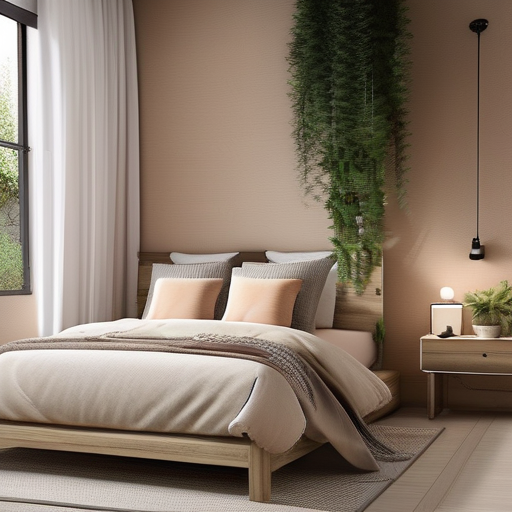

In [ ]:
# output
image.save("output.jpg")
image